# 05 - Exploratory data analysis
**Heat, Rain & Harvest.** Phase 5: look at the data before testing anything.

Inputs (built by `src/`): `data/processed/model_wheat.parquet`, `model_rice.parquet`, Census 2011 district polygons.
All yields are on fixed 2011 districts. "Anomaly" = deviation from each district's own linear trend
(full-sample trend: **descriptive only**, see DECISIONS D14). Figures are saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # run from notebooks/ or root
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import PROCESSED, FIGURES
from src.boundaries import load_pc11_districts

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
def save(fig, name):                      # every figure also goes to reports/figures/
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

w = pd.read_parquet(PROCESSED / "model_wheat.parquet")
r = pd.read_parquet(PROCESSED / "model_rice.parquet")
ws, rs = w[w.in_sample], r[r.in_sample]  # analysis samples (area >= 1000 ha, clean yield)
geo = load_pc11_districts()
print(f"wheat sample {len(ws):,} rows / {ws.unit_id.nunique()} districts; rice sample {len(rs):,} / {rs.unit_id.nunique()}")

wheat sample 9,793 rows / 444 districts; rice sample 13,052 / 575


## 1. What do yields look like?

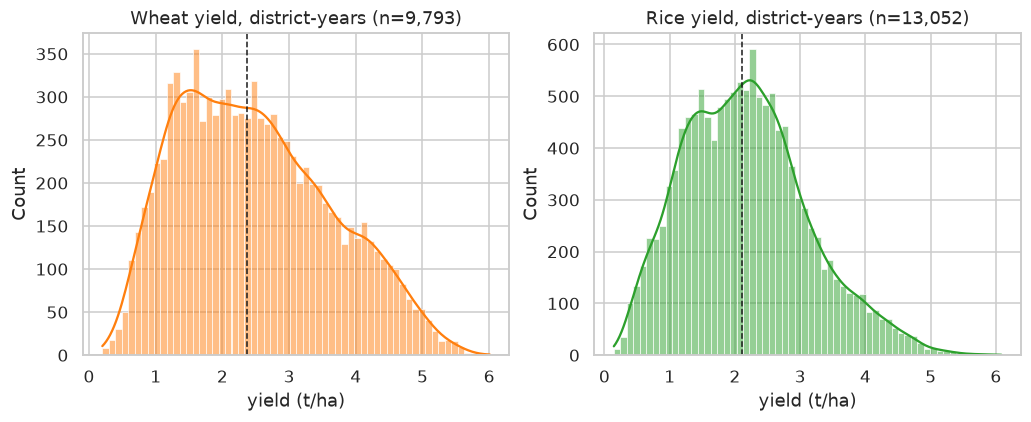

         count  mean   std   min   25%   50%   75%   max
wheat   9793.0  2.49  1.14  0.20  1.56  2.37  3.29  6.01
rice   13052.0  2.17  0.96  0.14  1.44  2.11  2.75  6.08
skewness: 0.41 0.48


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, d, name in ((ax[0], ws, "Wheat"), (ax[1], rs, "Rice")):
    sns.histplot(d.yield_t_ha, bins=60, kde=True, ax=a, color="tab:orange" if name == "Wheat" else "tab:green")
    a.axvline(d.yield_t_ha.median(), ls="--", c="k", lw=1)
    a.set(title=f"{name} yield, district-years (n={len(d):,})", xlabel="yield (t/ha)")
save(fig, "05_yield_distributions"); plt.show()
print(pd.DataFrame({"wheat": ws.yield_t_ha.describe(), "rice": rs.yield_t_ha.describe()}).round(2).T)
print("skewness:", round(ws.yield_t_ha.skew(), 2), round(rs.yield_t_ha.skew(), 2))

Both distributions are wide because they mix very different regions (irrigated Punjab vs rainfed central India).
That is why the analysis works with **each district's deviation from its own trend**, not raw yields.

## 2. National trends: yield and climate

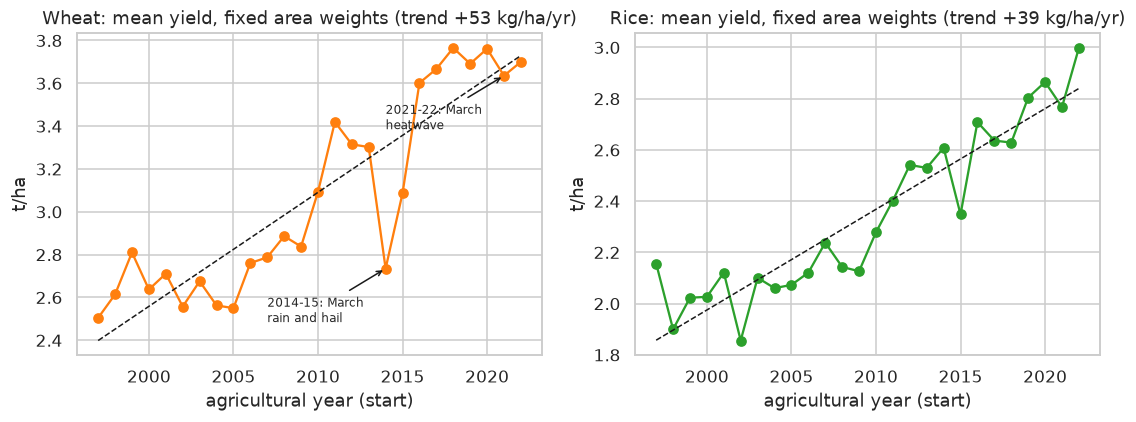

In [3]:
# FIXED weights = each district's mean crop area in 1997-2017. Using each year's own area would let
# reporting changes move the national average (Madhya Pradesh's area series jumps from 2018: DECISIONS D15).
fixed_w = {d.crop.iloc[0]: d[d.year <= 2017].groupby("unit_id").area_ha.mean() for d in (ws, rs)}
def wavg(d, col):                              # fixed-area-weighted mean per year, ignoring missing values
    wts = d.unit_id.map(fixed_w[d.crop.iloc[0]])
    ok = d[col].notna() & wts.notna()
    g = pd.DataFrame({"y": d.year[ok], "v": d[col][ok], "w": wts[ok]})
    return g.groupby("y").apply(lambda x: np.average(x.v, weights=x.w), include_groups=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, d, name, c in ((ax[0], ws, "Wheat", "tab:orange"), (ax[1], rs, "Rice", "tab:green")):
    s = wavg(d, "yield_t_ha")
    a.plot(s.index, s.values, marker="o", c=c)
    z = np.polyfit(s.index, s.values, 1); a.plot(s.index, np.polyval(z, s.index), "k--", lw=1)
    a.set(title=f"{name}: mean yield, fixed area weights (trend {z[0]*1000:+.0f} kg/ha/yr)", xlabel="agricultural year (start)", ylabel="t/ha")
sw = wavg(ws, "yield_t_ha")
for yr, label in ((2014, "2014-15: March\nrain and hail"), (2021, "2021-22: March\nheatwave")):
    ax[0].annotate(label, xy=(yr, sw[yr]), xytext=(yr - 7, sw[yr] - 0.25), fontsize=8, arrowprops=dict(arrowstyle="->", color="k"))
save(fig, "05_national_yield_trends"); plt.show()

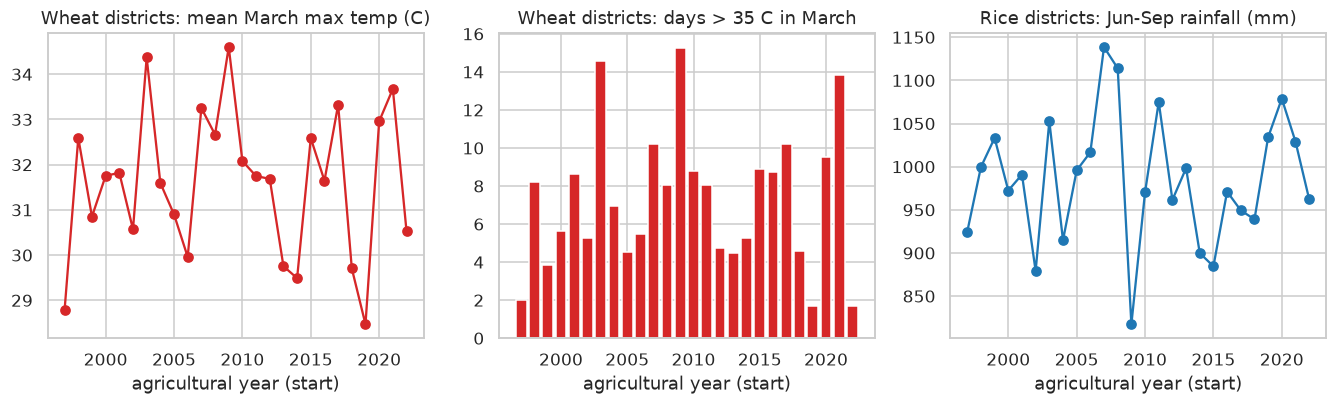

mar_tmax_mean: linear trend +0.01 per decade (fixed area weights, descriptive)
mar_hot_days_35: linear trend +0.28 per decade (fixed area weights, descriptive)
rain_jun_sep: linear trend +2.35 per decade (fixed area weights, descriptive)


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
s = wavg(ws, "mar_tmax_mean"); ax[0].plot(s, marker="o", c="tab:red"); ax[0].set(title="Wheat districts: mean March max temp (C)")
s = wavg(ws, "mar_hot_days_35"); ax[1].bar(s.index, s.values, color="tab:red"); ax[1].set(title="Wheat districts: days > 35 C in March")
s = wavg(rs, "rain_jun_sep"); ax[2].plot(s, marker="o", c="tab:blue"); ax[2].set(title="Rice districts: Jun-Sep rainfall (mm)")
for a in ax: a.set_xlabel("agricultural year (start)")
save(fig, "05_climate_trends"); plt.show()
for col, d in (("mar_tmax_mean", ws), ("mar_hot_days_35", ws), ("rain_jun_sep", rs)):
    s = wavg(d, col); z = np.polyfit(s.index, s.values, 1)
    print(f"{col}: linear trend {z[0]*10:+.2f} per decade (fixed area weights, descriptive)")

**Data note (D15).** Madhya Pradesh's reported wheat *area and production* roughly double between 2017 and 2019
(e.g. Shivpuri 76,900 ha -> 311,478 ha) while district *yields* stay in their usual range. This looks like a break in the
reporting series, not in yields. National averages therefore use fixed area weights, models include year effects,
and Phase 8 checks results without Madhya Pradesh 2018+.

## 3. Does weather move yield? (within-district view)

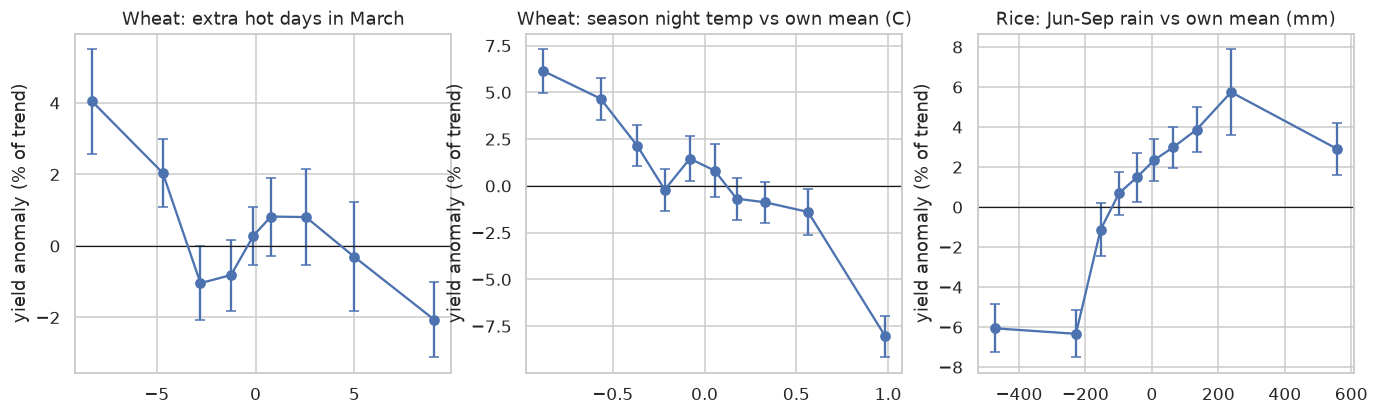

In [5]:
def within(d, col):                              # deviation from the district's own mean
    return d[col] - d.groupby("unit_id")[col].transform("mean")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
pairs = [(ws, "mar_hot_days_35", "Wheat: extra hot days in March"), (ws, "tmin_mean", "Wheat: season night temp vs own mean (C)"),
         (rs, "rain_jun_sep", "Rice: Jun-Sep rain vs own mean (mm)")]
for a, (d, col, title) in zip(ax, pairs):
    x = within(d, col); y = d.yield_rel_anom * 100
    bins = pd.qcut(x, 10, duplicates="drop")                        # 10 equal-size groups
    g = pd.DataFrame({"x": x, "y": y}).groupby(bins, observed=True).agg(x=("x", "mean"), y=("y", "mean"), se=("y", "sem"))
    a.errorbar(g.x, g.y, yerr=1.96 * g.se, fmt="o-", capsize=3)
    a.axhline(0, c="k", lw=.8); a.set(title=title, ylabel="yield anomaly (% of trend)")
save(fig, "05_binned_weather_vs_yield"); plt.show()

Binned scatter: districts are grouped into 10 bins of the weather deviation; each point is the mean yield
anomaly in that bin with a 95% interval. This shows the *shape* of the relation without 10,000 overlapping points.

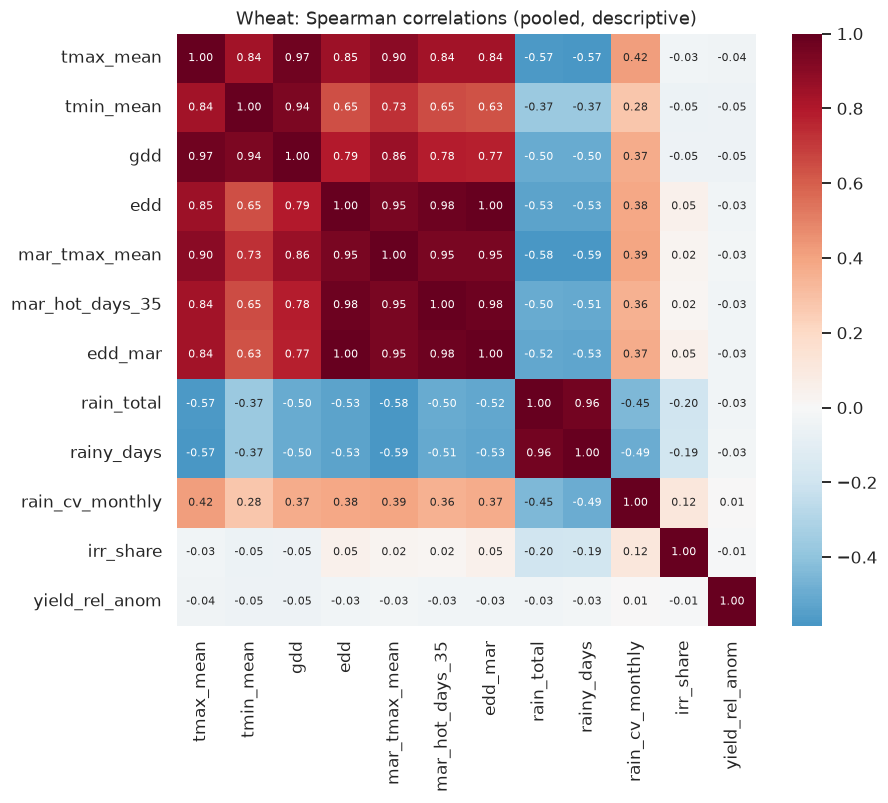

In [6]:
wcols = ["tmax_mean", "tmin_mean", "gdd", "edd", "mar_tmax_mean", "mar_hot_days_35", "edd_mar", "rain_total", "rainy_days", "rain_cv_monthly", "irr_share", "yield_rel_anom"]
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(ws[wcols].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Wheat: Spearman correlations (pooled, descriptive)")
save(fig, "05_wheat_feature_correlations"); plt.show()

Many heat features are strongly correlated with each other (e.g. `edd` and `edd_mar`, `tmax_mean` and `gdd`).
That **multicollinearity** matters for regression (unstable coefficients) and is handled in Phase 7 (feature selection, PCA) and Phase 8 (Ridge).

## 4. Maps (Census 2011 districts)

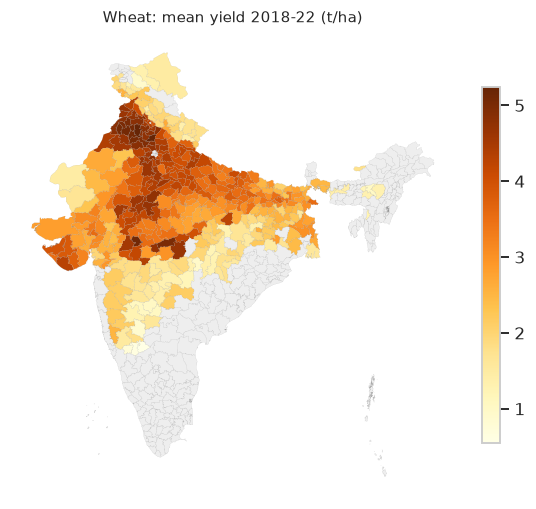

In [7]:
def dmap(values, title, name, cmap="viridis", center=None, ax=None):
    g = geo.merge(values.rename("v").reset_index().rename(columns={"unit_id": "district_id"}), on="district_id", how="left")
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(6.5, 7))
    kw = dict(column="v", cmap=cmap, legend=True, linewidth=0.05, edgecolor="grey",
              missing_kwds=dict(color="#eeeeee", label="no data"), legend_kwds=dict(shrink=0.6))
    if center is not None:
        lim = np.nanpercentile(np.abs(g.v - center), 98); kw.update(vmin=center - lim, vmax=center + lim)
    g.plot(ax=ax, **kw); ax.set_axis_off(); ax.set_title(title, fontsize=10)
    if own: save(ax.figure, name); plt.show()

dmap(ws[ws.year >= 2018].groupby("unit_id").yield_t_ha.mean(), "Wheat: mean yield 2018-22 (t/ha)", "05_map_wheat_yield", "YlOrBr")

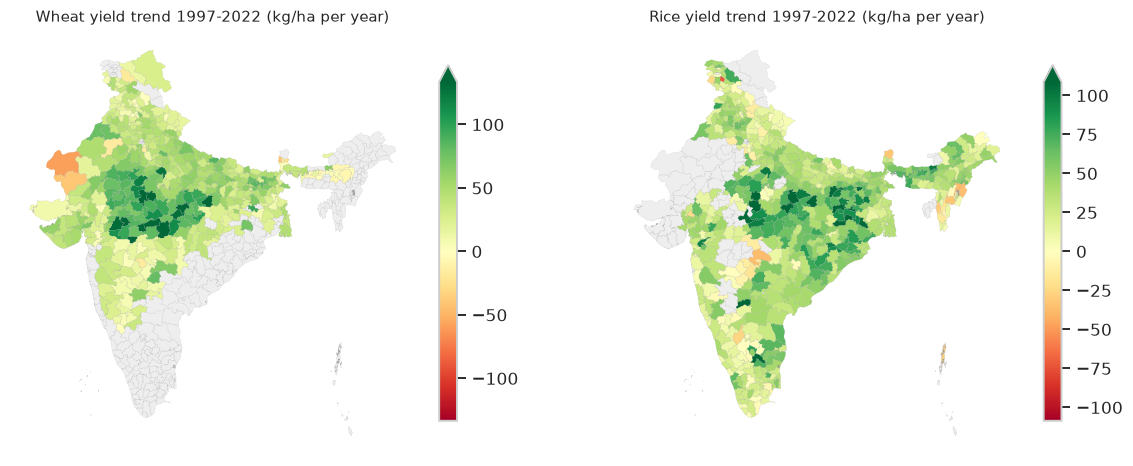

In [8]:
def slope(g):                                    # kg/ha per year from a per-district linear fit
    return np.polyfit(g.year, g.yield_t_ha, 1)[0] * 1000 if g.year.nunique() >= 8 else np.nan
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
dmap(ws.groupby("unit_id").apply(slope, include_groups=False), "Wheat yield trend 1997-2022 (kg/ha per year)", None, "RdYlGn", 0, ax[0])
dmap(rs.groupby("unit_id").apply(slope, include_groups=False), "Rice yield trend 1997-2022 (kg/ha per year)", None, "RdYlGn", 0, ax[1])
save(fig, "05_map_yield_trends"); plt.show()

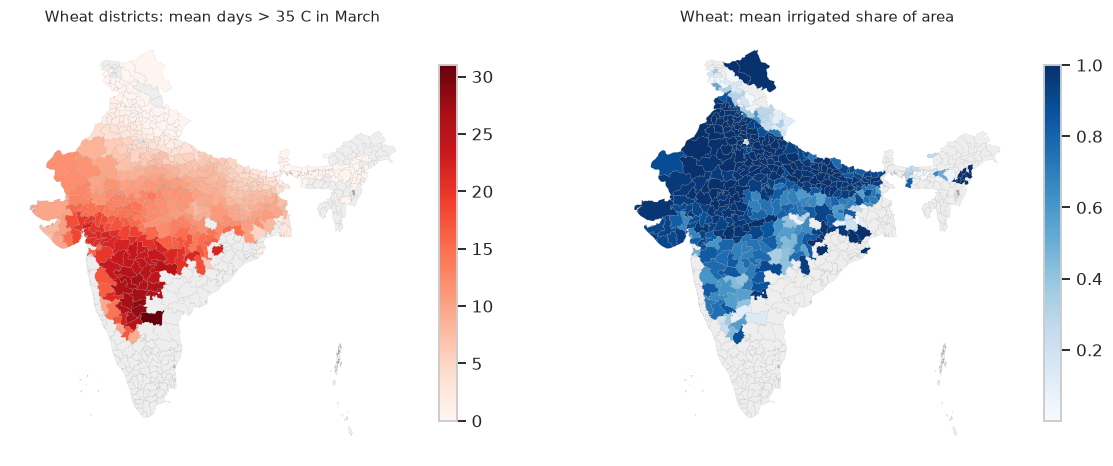

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
dmap(ws.groupby("unit_id").mar_hot_days_35.mean(), "Wheat districts: mean days > 35 C in March", None, "Reds", ax=ax[0])
dmap(ws.groupby("unit_id").irr_share.mean(), "Wheat: mean irrigated share of area", None, "Blues", ax=ax[1])
save(fig, "05_map_heat_irrigation"); plt.show()

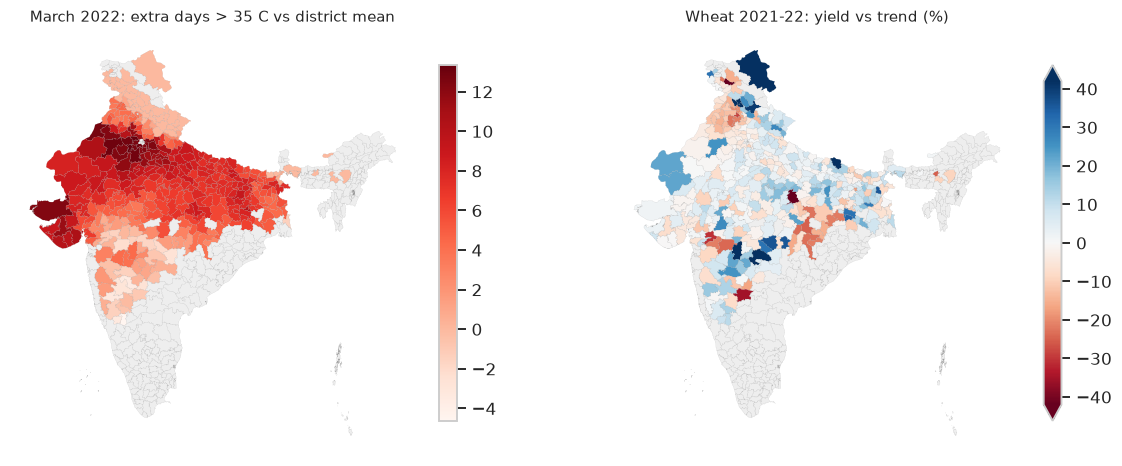

2021-22 wheat: share of sample districts below trend: 0.446
  Punjab+Haryana: median anomaly -9.8%, mean extra hot March days 6.4
  Uttar Pradesh: median anomaly +2.7%, mean extra hot March days 8.0
  Madhya Pradesh: median anomaly +2.3%, mean extra hot March days 5.1
  Rajasthan: median anomaly +1.7%, mean extra hot March days 9.2


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
y21 = ws[ws.year == 2021].set_index("unit_id")
dmap(y21.mar_hot_days_35 - ws.groupby("unit_id").mar_hot_days_35.mean(), "March 2022: extra days > 35 C vs district mean", None, "Reds", ax=ax[0])
dmap(y21.yield_rel_anom * 100, "Wheat 2021-22: yield vs trend (%)", None, "RdBu", 0, ax[1])
save(fig, "05_map_heatwave_2022"); plt.show()
print("2021-22 wheat: share of sample districts below trend:", round((y21.yield_rel_anom < 0).mean(), 3))
for name, ids in (("Punjab+Haryana", [3, 6]), ("Uttar Pradesh", [9]), ("Madhya Pradesh", [23]), ("Rajasthan", [8])):
    s = y21[y21.state_id.isin(ids)]
    print(f"  {name}: median anomaly {s.yield_rel_anom.median()*100:+.1f}%, mean extra hot March days "
          f"{(s.mar_hot_days_35 - ws.groupby('unit_id').mar_hot_days_35.mean().reindex(s.index)).mean():.1f}")

The heatwave covered the whole north-west and centre, but losses were concentrated in Punjab and Haryana.
Possible reasons to test later: wheat there is sown later or reaches grain filling during the hottest weeks, and its yields
are already near the ceiling. This is a hypothesis, not a finding.

## 5. A first look at the irrigation question

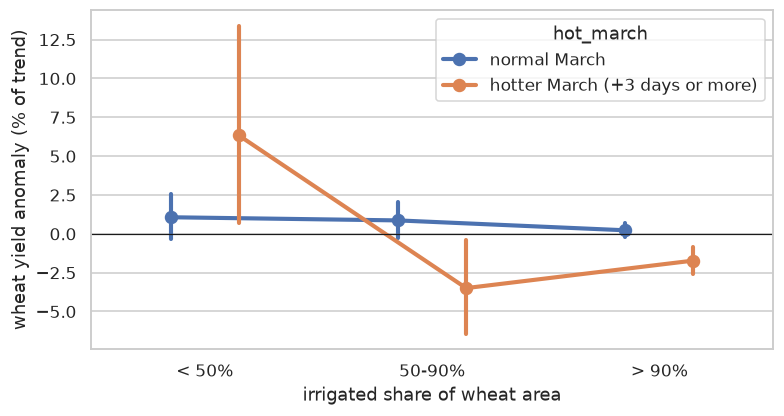

                                           count   mean
irrigation hot_march                                   
< 50%      hotter March (+3 days or more)    162  0.063
           normal March                     1050  0.011
50-90%     hotter March (+3 days or more)    352 -0.035
           normal March                     1183  0.009
> 90%      hotter March (+3 days or more)   1236 -0.017
           normal March                     3931  0.002


In [11]:
d = ws.dropna(subset=["irr_share", "mar_hot_days_35"]).copy()
d["hot_march"] = np.where(within(d, "mar_hot_days_35") > 3, "hotter March (+3 days or more)", "normal March")
d["irrigation"] = pd.cut(d.irr_share, [0, .5, .9, 1.0001], labels=["< 50%", "50-90%", "> 90%"], include_lowest=True)
fig, ax = plt.subplots(figsize=(8, 4))
sns.pointplot(data=d, x="irrigation", y=d.yield_rel_anom * 100, hue="hot_march", dodge=.3, errorbar=("ci", 95), ax=ax)
ax.axhline(0, c="k", lw=.8); ax.set(ylabel="wheat yield anomaly (% of trend)", xlabel="irrigated share of wheat area")
save(fig, "05_irrigation_x_heat_preview"); plt.show()
print(d.groupby(["irrigation", "hot_march"], observed=True).yield_rel_anom.agg(["count", "mean"]).round(3))

This is only a **preview**: if irrigation protects against heat, the gap between "hotter March" and "normal March"
should shrink as irrigation rises. The formal test (interaction term in a fixed-effects regression, with year effects
and clustered errors) is in Phase 6/8. Group sizes differ a lot, so the intervals differ in width.

## 6. What EDA tells us (to carry forward)
- Yields are strongly regional, so all tests use within-district anomalies and district fixed effects.
- Heat features are highly correlated with each other, so expect multicollinearity; use Ridge, PCA or feature selection.
- Missing data: LUS (irrigation) starts 1998-99; island districts have no rainfall; small-area districts are excluded.
- The 2021-22 heatwave is a natural test case for the forecast and the warming scenarios.